# LAB 1 - Data Preprocessing: Handling Missing Data

**Dataset:** `Diabetes Missing Data.csv`

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Diabetes Missing Data.csv")
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (768, 9)


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 2. Inspect data types and detect missing values

In [2]:
print(df.dtypes)
print()
print("Missing values per column:")
print(df.isnull().sum())

Pregnant               int64
Glucose              float64
Diastolic_BP         float64
Skin_Fold            float64
Serum_Insulin        float64
BMI                  float64
Diabetes_Pedigree    float64
Age                    int64
Class                  int64
dtype: object

Missing values per column:
Pregnant               0
Glucose                5
Diastolic_BP          35
Skin_Fold            227
Serum_Insulin        374
BMI                   11
Diabetes_Pedigree      0
Age                    0
Class                  0
dtype: int64


In [3]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_%": (df.isnull().sum() / len(df) * 100).round(2)
})
missing

,Missing_Count,Missing_%
Pregnant,0,0.00
Glucose,5,0.65
Diastolic_BP,35,4.56
Skin_Fold,227,29.56
Serum_Insulin,374,48.70
BMI,11,1.43
Diabetes_Pedigree,0,0.00
Age,0,0.00
Class,0,0.00


## 3. Handle the missing values

| Strategy | Columns | Reason |
|---|---|---|
| **Mean** | Glucose, Diastolic_BP, BMI | roughly symmetric distributions, few missing values |
| **Median** | Skin_Fold, Serum_Insulin | heavily skewed with many missing values, median resists outliers |
| **Mode**  | Class | categorical target, mode is the only sensible fill |

In [4]:
df_filled = df.copy()

for c in ["Glucose", "Diastolic_BP", "BMI"]:
    df_filled[c] = df_filled[c].fillna(df_filled[c].mean())

for c in ["Skin_Fold", "Serum_Insulin"]:
    df_filled[c] = df_filled[c].fillna(df_filled[c].median())

df_filled["Class"] = df_filled["Class"].fillna(df_filled["Class"].mode()[0])

print("Missing values after imputation:")
print(df_filled.isnull().sum())

Missing values after imputation:
Pregnant             0
Glucose              0
Diastolic_BP         0
Skin_Fold            0
Serum_Insulin        0
BMI                  0
Diabetes_Pedigree    0
Age                  0
Class                0
dtype: int64


In [5]:
df_filled.head(10)

,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.000000,35.0,125.0,33.600000,0.627,50,1
1,1,85.0,66.000000,29.0,125.0,26.600000,0.351,31,0
2,8,183.0,64.000000,29.0,125.0,23.300000,0.672,32,1
3,1,89.0,66.000000,23.0,94.0,28.100000,0.167,21,0
4,0,137.0,40.000000,35.0,168.0,43.100000,2.288,33,1
5,5,116.0,74.000000,29.0,125.0,25.600000,0.201,30,0
6,3,78.0,50.000000,32.0,88.0,31.000000,0.248,26,1
7,10,115.0,72.405184,29.0,125.0,35.300000,0.134,29,0
8,2,197.0,70.000000,45.0,543.0,30.500000,0.158,53,1
9,8,125.0,96.000000,29.0,125.0,32.457464,0.232,54,1


In [6]:
df_filled.describe()

,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.108073,140.671875,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.435949,12.096346,8.791221,86.383060,6.875151,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.202592,29.000000,125.000000,32.400000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 4. Exploratory analysis of the cleaned data

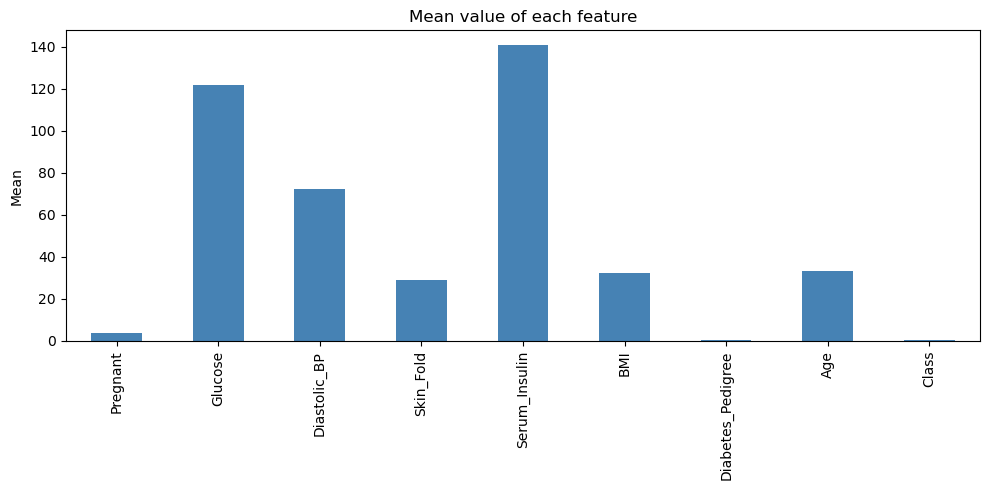

In [7]:
features = df_filled.columns

plt.figure(figsize=(10, 5))
df_filled[features].mean().plot(kind="bar", color="steelblue")
plt.title("Mean value of each feature")
plt.ylabel("Mean")
plt.tight_layout()
plt.show()

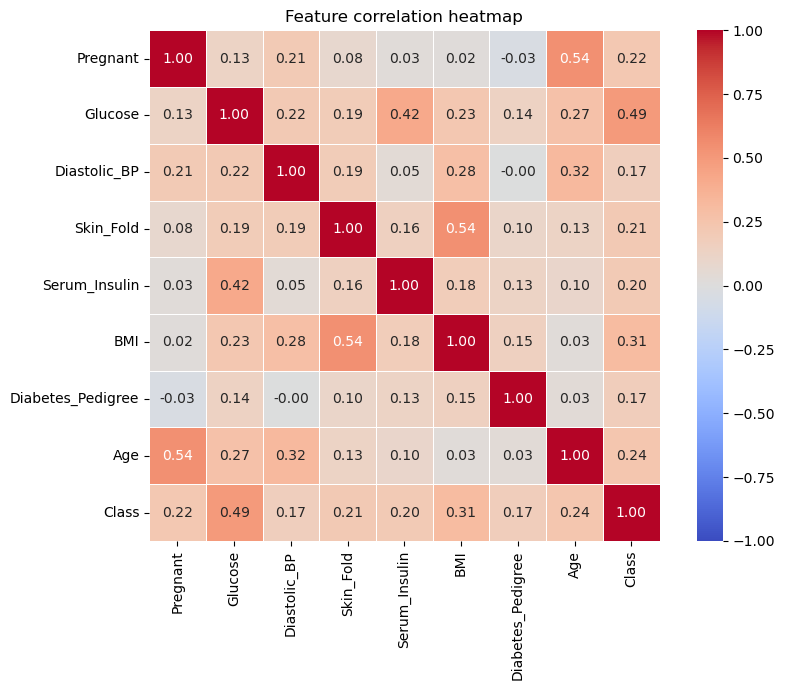

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_filled.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

## 5. Save the cleaned dataset (input for LAB 2)

In [9]:
df_filled.to_csv("LAB1_cleaned_data.csv", index=False)
print("Saved LAB1_cleaned_data.csv | shape:", df_filled.shape)

Saved LAB1_cleaned_data.csv | shape: (768, 9)
